# PSPNet–ResNet-50 trên Kaggle — ADE20K 150 lớp

Notebook tự chứa mã để so sánh trực tiếp với `fcn-kaggle-ade20k.ipynb` và `deeplabv3-kaggle-ade20k.ipynb` trong cùng giao thức Kaggle.

1. Upload notebook vào Kaggle, bật GPU và Internet nếu cần tải dữ liệu/weights. Chỉ dùng GPU 0.
2. Attach ADEChallengeData2016 gốc đã giải nén; notebook tự tìm root hoặc tải bản chính thức nếu chưa có.
3. Chạy tuần tự: kiểm tra môi trường → chuẩn bị dữ liệu → preflight → train → đánh giá cuối.
4. Save Version để giữ output; phiên mới resume từ `last.pt` đã lưu.

**Cùng cấu hình hai notebook đối chứng:** TorchVision ResNet-50 ImageNet-1K V1, output stride 8, crop 384, micro-batch 2 × accumulation 8, seed 17, SGD/poly, 10.000 updates, freeze BN running statistics, train FP16, eval FP32.

**PPM mặc định `{1,2,3,6}`**, mỗi nhánh 512 kênh. Muốn thử `{1,2,3,7}`, đổi `PPM_BINS` và tên thí nghiệm trước khi chạy. Kiến trúc này dùng standard-stem TorchVision để có cùng backbone với FCN/DeepLabV3; khác deep-stem ResNet-101 của các notebook Modal cũ. Bilinear interpolation dùng `align_corners=False` như nhóm Kaggle. Không nhập checkpoint Modal.

**Bản stable v2:** backbone LR 0,001, head LR tối đa 0,01; warmup 500 bước từ hệ số 0,1; clip gradient norm 1,0. FP16 overflow sẽ thử lại cùng batch/RNG bằng FP32 và được ghi trong log. Không bỏ qua batch hay tính lần thử thất bại thành update thành công.

Dùng tên output mới có `stable_v2`, chạy lại từ ImageNet; không resume checkpoint/lock v1. Nếu đã chạy v1, dùng cùng v2 cho cả ba mô hình để giữ tính công bằng. Bản sửa giữ nguyên crop, backbone, seed, batch hiệu dụng và giao thức đánh giá.


## 1. Kiểm tra môi trường

Dùng torch/torchvision có sẵn của Kaggle, không cài đè CUDA. Nếu import lỗi do binary không tương thích, tạo session Kaggle sạch. Không cần mmcv, Modal hay transformers.


In [1]:
import os, sys, json, subprocess, importlib.util
from pathlib import Path
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
try:
    import torch, torchvision, numpy as np
    from PIL import Image
    import matplotlib.pyplot as plt
except Exception as error:
    raise RuntimeError("Không import được bộ torch/torchvision/Pillow của Kaggle. Hãy khởi động session sạch.") from error
assert torch.cuda.is_available(), "Bật GPU trong Kaggle Settings → Accelerator rồi restart session."
torch.set_num_threads(min(4, os.cpu_count() or 1))
print("Python:", sys.version)
print("torch:", torch.__version__, "torchvision:", torchvision.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM GiB:", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))
print("Số GPU:", torch.cuda.device_count(), "— notebook chỉ dùng cuda:0")


Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
torch: 2.11.0+cu128 torchvision: 0.26.0+cu128
GPU: Tesla T4
VRAM GiB: 14.56
Số GPU: 2 — notebook chỉ dùng cuda:0


## 2. Cấu hình

Giữ cấu hình train/eval giống notebook đối chứng. Nếu preflight OOM, giảm micro-batch về 1 và tăng accumulation lên 16 cho **cả ba** mô hình, đổi EXPERIMENT_NAME. Không tự giảm cấu hình giữa một thí nghiệm. SESSION_HOURS dừng ở ranh giới update và lưu checkpoint; nó không kéo dài giới hạn phiên của Kaggle.

LR và các tham số warmup/clipping được khóa trong giao thức; không chỉnh giữa một lần train.


In [2]:
MODEL = "pspnet_resnet50"
PPM_BINS = [1, 2, 3, 6]  # đổi thành [1,2,3,7] cho một thí nghiệm mới
EXPERIMENT_NAME = "pspnet_r50_b6_ade20k_s17_c384_b16_10k_stable_v2"
DATA_ROOT = ""  # tự tìm dưới /kaggle/input; hoặc nhập đường dẫn ADEChallengeData2016
DOWNLOAD_IF_MISSING = True
BACKBONE_WEIGHTS = ""  # offline: đường dẫn resnet50-0676ba61.pth (ImageNet V1)
RESUME_FROM = "auto"  # "auto": tự tìm last.pt của EXPERIMENT_NAME dưới /kaggle/input; "" = train từ đầu; hoặc đường dẫn last.pt
SESSION_HOURS = 7.0
TRAIN_STEPS_THIS_SESSION = 10000  # giảm để chia phiên; không đổi max_steps
WORK = Path("/kaggle/working")
OUTPUT = WORK / EXPERIMENT_NAME
OUTPUT.mkdir(parents=True, exist_ok=True)
os.chdir(WORK)
cfg = {
    "model": MODEL, "ppm_bins": PPM_BINS, "seed": 17, "classes": 150, "crop": 384,
    "micro_batch": 2, "accumulation": 8, "max_steps": 10000,
    "lr": 0.001, "head_lr_multiplier": 10.0, "momentum": 0.9, "weight_decay": 1e-4,
    "poly_power": 0.9, "warmup_steps": 500, "warmup_start_factor": 0.1, "max_grad_norm": 1.0, "precision": "amp_fp16", "bn_policy": "freeze_all_running_stats_train_affine",
    "scale_range": [0.5, 2.0], "rotation": 10.0,
    "eval_base_size": 512, "eval_crop": 384, "eval_every": 1000, "eval_subset": 100,
    "preflight_updates": 5, "save_every": 250, "log_every": 50, "workers": 2,
    "session_hours": SESSION_HOURS, "session_steps": TRAIN_STEPS_THIS_SESSION,
    "benchmark_warmup": 30, "benchmark_repeats": 100,
    "backbone_weights": BACKBONE_WEIGHTS, "output_dir": str(OUTPUT),
}
assert cfg["micro_batch"] * cfg["accumulation"] == 16
assert cfg["session_steps"] > 0 and cfg["session_hours"] > 0
print(json.dumps(cfg, indent=2))


{
  "model": "pspnet_resnet50",
  "ppm_bins": [
    1,
    2,
    3,
    6
  ],
  "seed": 17,
  "classes": 150,
  "crop": 384,
  "micro_batch": 2,
  "accumulation": 8,
  "max_steps": 10000,
  "lr": 0.001,
  "head_lr_multiplier": 10.0,
  "momentum": 0.9,
  "weight_decay": 0.0001,
  "poly_power": 0.9,
  "warmup_steps": 500,
  "warmup_start_factor": 0.1,
  "max_grad_norm": 1.0,
  "precision": "amp_fp16",
  "bn_policy": "freeze_all_running_stats_train_affine",
  "scale_range": [
    0.5,
    2.0
  ],
  "rotation": 10.0,
  "eval_base_size": 512,
  "eval_crop": 384,
  "eval_every": 1000,
  "eval_subset": 100,
  "preflight_updates": 5,
  "save_every": 250,
  "log_every": 50,
  "workers": 2,
  "session_hours": 7.0,
  "session_steps": 10000,
  "benchmark_warmup": 30,
  "benchmark_repeats": 100,
  "backbone_weights": "",
  "output_dir": "/kaggle/working/pspnet_r50_b6_ade20k_s17_c384_b16_10k_stable_v2"
}


## 3. Ghi runner và kiến trúc PSPNet

Mã train/eval/resume giống hai notebook Kaggle trước. Phần bổ sung gồm `PyramidPooling` và `KagglePSPNet`: layer4 → PPM 1236 → Conv3×3 4096→512 → BN/ReLU/Dropout → Conv1×1 150 lớp. Auxiliary head lấy từ layer3, hệ số loss 0,4. Không cần upload file Python đi kèm.


In [3]:
%%writefile /kaggle/working/kaggle_segmentation.py
"""Shared, embedded runner for the standalone Kaggle PSPNet notebook (stable protocol v2).

TorchVision ResNet-50 / ADE20K; no Modal, mmcv, or segmentation-pretrained weights.
"""
from __future__ import annotations

import contextlib
import csv
import gc
import hashlib
import json
import math
import os
from pathlib import Path
import random
import shutil
import time
import urllib.request
import zipfile

import numpy as np
from PIL import Image, ImageFilter, ImageOps
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, Sampler
import torchvision
from torchvision.models import ResNet50_Weights
from torchvision.models.segmentation import fcn_resnet50, deeplabv3_resnet50

MEAN = np.array([.485, .456, .406], dtype=np.float32)
STD = np.array([.229, .224, .225], dtype=np.float32)
ADE_URL = "https://data.csail.mit.edu/places/ADEchallenge/ADEChallengeData2016.zip"
PROTOCOL_KEYS = ("model", "seed", "classes", "crop", "micro_batch", "accumulation",
                 "max_steps", "lr", "head_lr_multiplier", "momentum", "weight_decay",
                 "poly_power", "warmup_steps", "warmup_start_factor", "max_grad_norm",
                 "precision", "bn_policy", "scale_range", "rotation",
                 "eval_base_size", "eval_crop", "eval_every", "eval_subset", "ppm_bins")


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
    os.replace(tmp, path)


def append_csv(path, row):
    path = Path(path)
    exists = path.exists()
    with path.open("a", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(row))
        if not exists:
            writer.writeheader()
        writer.writerow(row)


def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    # CUDA interpolation backward is not guaranteed bitwise deterministic.
    torch.use_deterministic_algorithms(True, warn_only=True)


def environment():
    return {"torch": str(torch.__version__), "torchvision": str(torchvision.__version__),
            "numpy": str(np.__version__), "cuda": torch.version.cuda,
            "cudnn": torch.backends.cudnn.version(),
            "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"}


def read_mask(path, classes=150):
    with Image.open(path) as im:
        mask = np.array(im, dtype=np.int64)
    if mask.ndim != 2 or mask.min() < 0 or mask.max() > classes:
        raise ValueError(f"Expected original ADE20K labels 0..{classes}: {path}")
    return np.where(mask == 0, 255, mask - 1).astype(np.uint8)


def pairs(root, split):
    root = Path(root)
    result = [(p, root / "annotations" / split / (p.stem + ".png"))
              for p in sorted((root / "images" / split).glob("*.jpg"))]
    if not result or any(not mask.is_file() for _, mask in result):
        raise FileNotFoundError(f"Missing original ADE20K image/mask pairs in {root}, {split}")
    return result


def find_dataset(explicit="", search_root="/kaggle/input"):
    if explicit:
        root = Path(explicit)
        pairs(root, "training")
        pairs(root, "validation")
        return root
    candidates = []
    search = Path(search_root)
    if search.exists():
        for train in search.rglob("images/training"):
            root = train.parent.parent
            if (root / "annotations/training").is_dir() and (root / "images/validation").is_dir():
                candidates.append(root)
    downloaded = Path("/kaggle/working/data/ADEChallengeData2016")
    if downloaded.is_dir():
        candidates.append(downloaded)
    candidates = sorted(set(candidates))
    if len(candidates) > 1:
        raise ValueError(f"Multiple ADE20K roots: {candidates}. Set DATA_ROOT explicitly.")
    return candidates[0] if candidates else None


def download_dataset(parent="/kaggle/working/data", url=ADE_URL):
    parent = Path(parent)
    parent.mkdir(parents=True, exist_ok=True)
    archive = parent / "ADEChallengeData2016.zip"
    if not archive.exists():
        partial = archive.with_suffix(".download")
        try:
            with urllib.request.urlopen(url, timeout=90) as response, partial.open("wb") as f:
                expected = int(response.headers.get("Content-Length", "0"))
                shutil.copyfileobj(response, f, length=1024 * 1024)
            if expected and partial.stat().st_size != expected:
                raise IOError("Incomplete ADE20K download")
            if not zipfile.is_zipfile(partial):
                raise ValueError("Download is not a ZIP file")
            os.replace(partial, archive)
        except Exception as error:
            raise RuntimeError("Could not download ADE20K. Enable Internet or attach an extracted "
                               "ADEChallengeData2016 Kaggle Dataset and set DATA_ROOT.") from error
    with zipfile.ZipFile(archive) as z:
        for item in z.infolist():
            if not (parent / item.filename).resolve().is_relative_to(parent.resolve()):
                raise ValueError("Unsafe ZIP path")
        z.extractall(parent)
    return parent / "ADEChallengeData2016"


def prepare(cfg, root, strict=True):
    """Validate original labels and fingerprint actual image/mask contents."""
    if cfg["model"] not in ("fcn_resnet50", "deeplabv3_resnet50", "pspnet_resnet50") or cfg["classes"] != 150:
        raise ValueError("Expected PSPNet/FCN/DeepLabV3 ResNet-50 with 150 ADE20K classes")
    for key in ("crop", "micro_batch", "accumulation", "max_steps", "eval_crop", "session_steps", "save_every"):
        if not isinstance(cfg[key], int) or cfg[key] < 1:
            raise ValueError(f"{key} must be a positive integer")
    if cfg["crop"] < 32 or cfg["session_hours"] <= 0 or cfg["eval_subset"] < 1:
        raise ValueError("Invalid crop/session budget/validation subset")
    if cfg["bn_policy"] != "freeze_all_running_stats_train_affine":
        raise ValueError("This runner uses frozen BN running statistics with trainable affine parameters")
    if not (0 <= cfg["warmup_steps"] < cfg["max_steps"]
            and 0 < cfg["warmup_start_factor"] <= 1 and cfg["max_grad_norm"] > 0):
        raise ValueError("Invalid warmup or gradient clipping configuration")
    if cfg["ppm_bins"] not in ([1, 2, 3, 6], [1, 2, 3, 7]):
        raise ValueError("ppm_bins must be [1,2,3,6] or [1,2,3,7]")
    output = Path(cfg["output_dir"])
    output.mkdir(parents=True, exist_ok=True)
    manifest = []
    train_hashes, duplicates = {}, []
    for split, expected in (("training", 20210), ("validation", 2000)):
        items = pairs(root, split)
        if strict and len(items) != expected:
            raise ValueError(f"{split}: expected {expected} images, got {len(items)}. "
                             "Use the full original ADEChallengeData2016 release.")
        for index, (image, mask) in enumerate(items):
            with Image.open(image) as im:
                size = im.size
            label = read_mask(mask, cfg["classes"])
            if label.shape != (size[1], size[0]):
                raise ValueError(f"Image/mask shape mismatch: {image}")
            digest = sha256(image)
            name = str(image.relative_to(root)).replace("\\", "/")
            manifest.append([name, str(mask.relative_to(root)).replace("\\", "/"), digest, sha256(mask)])
            if split == "training":
                train_hashes.setdefault(digest, []).append(name)
            elif digest in train_hashes:
                duplicates.append({"validation": name, "training": train_hashes[digest]})
            if (index + 1) % 2000 == 0:
                print("Validate/hash", split, index + 1, "/", len(items), flush=True)
    data_hash = hashlib.sha256(json.dumps(manifest, separators=(",", ":")).encode()).hexdigest()
    lock = {"protocol": {key: cfg[key] for key in PROTOCOL_KEYS}, "data_sha256": data_hash,
            "code_sha256": sha256(__file__), "environment": environment(),
            "initialization": "ResNet50 ImageNet-1K V1 backbone; new 150-class heads"}
    lock_path = output / "experiment_lock.json"
    if lock_path.exists() and json.loads(lock_path.read_text(encoding="utf-8")) != lock:
        raise ValueError("Protocol/data/code/environment changed. Restore the old settings or choose a NEW EXPERIMENT_NAME.")
    write_json(lock_path, lock)
    write_json(output / "data_manifest.json", manifest)
    write_json(output / "train_val_duplicates.json", duplicates)
    write_json(output / "config.json", cfg)
    print(f"Prepared. Train/val byte duplicates: {len(duplicates)}; official split preserved.")
    return lock


def require_lock(cfg, lock):
    if ({key: cfg[key] for key in PROTOCOL_KEYS} != lock["protocol"]
            or sha256(__file__) != lock["code_sha256"] or environment() != lock["environment"]):
        raise ValueError("Config/code/environment changed after prepare. Prepare a NEW experiment.")


def tensor_image(image):
    a = np.asarray(image, dtype=np.float32) / 255.
    return torch.from_numpy(((a - MEAN) / STD).transpose(2, 0, 1).copy())


class ADETrain(Dataset):
    def __init__(self, root, cfg):
        self.items, self.cfg = pairs(root, "training"), cfg

    def __len__(self):
        return len(self.items)

    def __getitem__(self, key):
        index, epoch = key
        cfg = self.cfg
        token = hashlib.sha256(f"{cfg['seed']}:{epoch}:{index}".encode()).digest()
        rng = random.Random(int.from_bytes(token[:8], "little"))
        image_path, mask_path = self.items[index]
        with Image.open(image_path) as im:
            image = im.convert("RGB")
        mask = Image.fromarray(read_mask(mask_path, cfg["classes"]))
        scale = rng.uniform(*cfg["scale_range"])
        size = (max(1, round(image.width * scale)), max(1, round(image.height * scale)))
        image = image.resize(size, Image.Resampling.BILINEAR)
        mask = mask.resize(size, Image.Resampling.NEAREST)
        angle = rng.uniform(-cfg["rotation"], cfg["rotation"])
        fill = tuple(int(round(v * 255)) for v in MEAN)
        image = image.rotate(angle, Image.Resampling.BILINEAR, fillcolor=fill)
        mask = mask.rotate(angle, Image.Resampling.NEAREST, fillcolor=255)
        if rng.random() < .5:
            image, mask = ImageOps.mirror(image), ImageOps.mirror(mask)
        if rng.random() < .5:
            image = image.filter(ImageFilter.GaussianBlur(rng.uniform(.1, 1.5)))
        crop = cfg["crop"]
        border = (0, 0, max(0, crop - image.width), max(0, crop - image.height))
        image, mask = ImageOps.expand(image, border, fill), ImageOps.expand(mask, border, 255)
        left, top = rng.randint(0, image.width - crop), rng.randint(0, image.height - crop)
        box = (left, top, left + crop, top + crop)
        return tensor_image(image.crop(box)), torch.from_numpy(np.array(mask.crop(box), dtype=np.int64))


class ResumeBatches(Sampler):
    """Deterministic data position; worker prefetch does not alter resume order."""
    def __init__(self, count, batch, seed, start_micro, stop_micro):
        self.count, self.batch, self.seed = count, batch, seed
        self.start, self.stop = start_micro, stop_micro
        if count < batch:
            raise ValueError("Training dataset smaller than micro_batch")

    def __len__(self):
        return self.stop - self.start

    def __iter__(self):
        epoch_cached, perm = -1, None
        for micro in range(self.start, self.stop):
            epoch, offset = divmod(micro, self.count // self.batch)
            if epoch != epoch_cached:
                perm = np.random.default_rng(self.seed + epoch).permutation(self.count)
                epoch_cached = epoch
            yield [(int(i), epoch) for i in perm[offset * self.batch:(offset + 1) * self.batch]]


class PyramidPooling(nn.Module):
    """PSPNet PPM with four pooling grids and 512 channels per branch."""
    def __init__(self, bins):
        super().__init__()
        self.bins = tuple(bins)
        self.features = nn.ModuleList([
            nn.Sequential(nn.AdaptiveAvgPool2d(size),
                          nn.Conv2d(2048, 512, 1, bias=False),
                          nn.BatchNorm2d(512), nn.ReLU(inplace=True))
            for size in self.bins])

    def forward(self, x):
        # Match the Kaggle FCN/DeepLabV3 interpolation convention.
        return torch.cat([x] + [F.interpolate(branch(x), size=x.shape[-2:],
                                              mode="bilinear", align_corners=False)
                                 for branch in self.features], dim=1)

class KagglePSPNet(nn.Module):
    """PSPNet head on the EXACT TorchVision R50 OS8 backbone/aux used by FCN.

    This uses the standard TorchVision stem for a common-backbone comparison;
    it does not import the deep-stem ResNet from the older Modal experiments.
    """
    def __init__(self, classes, bins):
        super().__init__()
        base = fcn_resnet50(weights=None, weights_backbone=None,
                            num_classes=classes, aux_loss=True)
        self.backbone = base.backbone
        self.aux_classifier = base.aux_classifier
        self.classifier = nn.Sequential(
            PyramidPooling(bins),
            nn.Conv2d(4096, 512, 3, padding=1, bias=False),
            nn.BatchNorm2d(512), nn.ReLU(inplace=True), nn.Dropout2d(.1),
            nn.Conv2d(512, classes, 1))

    def forward(self, x):
        size = x.shape[-2:]
        features = self.backbone(x)
        result = {"out": F.interpolate(self.classifier(features["out"]), size=size,
                                         mode="bilinear", align_corners=False)}
        if self.aux_classifier is not None:
            result["aux"] = F.interpolate(self.aux_classifier(features["aux"]), size=size,
                                           mode="bilinear", align_corners=False)
        return result


def make_model(cfg, pretrained=True):
    seed_all(cfg["seed"])
    builders = {"fcn_resnet50": fcn_resnet50, "deeplabv3_resnet50": deeplabv3_resnet50}
    if cfg["model"] == "pspnet_resnet50":
        model = KagglePSPNet(cfg["classes"], cfg["ppm_bins"])
    else:
        model = builders[cfg["model"]](weights=None, weights_backbone=None,
                                        num_classes=cfg["classes"], aux_loss=True)
    if pretrained:
        local = cfg.get("backbone_weights", "")
        try:
            state = (torch.load(local, map_location="cpu", weights_only=True) if local
                     else ResNet50_Weights.IMAGENET1K_V1.get_state_dict(progress=True, check_hash=True))
            state = {k: v for k, v in state.items() if not k.startswith("fc.")}
            model.backbone.load_state_dict(state, strict=True)
        except Exception as error:
            raise RuntimeError("ImageNet ResNet-50 V1 weights unavailable. Enable Internet, or attach "
                               "resnet50-0676ba61.pth and set BACKBONE_WEIGHTS. No random fallback.") from error
    return model


def train_mode(model):
    model.train()
    # Small physical batches: freeze ALL BN running statistics; affine parameters still learn.
    for module in model.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            module.eval()


def optimizer_for(model, cfg):
    return torch.optim.SGD([
        {"params": list(model.backbone.parameters()), "lr_scale": 1.0},
        {"params": list(model.classifier.parameters()) + list(model.aux_classifier.parameters()),
         "lr_scale": cfg["head_lr_multiplier"]}], lr=cfg["lr"],
        momentum=cfg["momentum"], weight_decay=cfg["weight_decay"])


def set_learning_rate(optimizer, cfg, step):
    factor = 1.0
    if step < cfg["warmup_steps"]:
        factor = cfg["warmup_start_factor"] + (1 - cfg["warmup_start_factor"]) * step / cfg["warmup_steps"]
    lr = cfg["lr"] * (1 - step / cfg["max_steps"]) ** cfg["poly_power"] * factor
    for group in optimizer.param_groups:
        group["lr"] = lr * group["lr_scale"]
    return lr


def amp_context(cfg, device):
    return (torch.autocast("cuda", dtype=torch.float16)
            if device.type == "cuda" and cfg["precision"] == "amp_fp16" else contextlib.nullcontext())


def make_scaler(cfg, device):
    enabled = device.type == "cuda" and cfg["precision"] == "amp_fp16"
    if hasattr(torch, "amp") and hasattr(torch.amp, "GradScaler"):
        return torch.amp.GradScaler("cuda", enabled=enabled, init_scale=1024.)
    return torch.cuda.amp.GradScaler(enabled=enabled, init_scale=1024.)


def update(model, optimizer, scaler, batches, cfg, device):
    """Unscale, clip, then step. Retry AMP failures on identical data/RNG in FP32.

    A failed forward/backward never advances SGD or the successful-update budget.
    Frozen BN statistics make a full retry free of running-stat side effects.
    """
    cpu_rng = torch.get_rng_state()
    cuda_rng = torch.cuda.get_rng_state_all() if device.type == "cuda" else []

    def restore_rng():
        torch.set_rng_state(cpu_rng)
        if cuda_rng:
            torch.cuda.set_rng_state_all(cuda_rng)

    def fail(message):
        optimizer.zero_grad(set_to_none=True)
        restore_rng()
        raise FloatingPointError(message)

    use_amp = scaler.is_enabled()
    fp32_fallback, last_failure = 0, ""
    for attempt in range(8):
        restore_rng()
        optimizer.zero_grad(set_to_none=True)
        total, correct, pixels = 0., 0, 0
        bad_forward = False
        for x, y in batches:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            if not (y != 255).any():
                raise ValueError("All-ignore batch; check ADE20K masks/augmentation.")
            with amp_context(cfg, device) if use_amp else contextlib.nullcontext():
                output = model(x)
            # CE is explicitly FP32 even when the convolution graph runs in FP16.
            loss = F.cross_entropy(output["out"].float(), y, ignore_index=255)
            loss = loss + .4 * F.cross_entropy(output["aux"].float(), y, ignore_index=255)
            if not torch.isfinite(loss):
                last_failure = "non-finite forward logits/loss"
                del output, x, y, loss
                bad_forward = True
                break
            scaler.scale(loss / len(batches)).backward()
            total += float(loss.detach()) / len(batches)
            with torch.no_grad():
                valid = y != 255
                correct += int(((output["out"].argmax(1) == y) & valid).sum())
                pixels += int(valid.sum())
            del output, x, y, loss
        if bad_forward:
            if not use_amp:
                fail("FP32 forward is non-finite. No update applied; check input/weights. " + last_failure)
            # Reducing GradScaler does not fix forward overflow. Rerun the WHOLE update in FP32.
            use_amp, fp32_fallback = False, 1
            print("AMP forward overflow: retrying same update in FP32", flush=True)
            continue
        scaler.unscale_(optimizer)
        norm = torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["max_grad_norm"])
        if torch.isfinite(norm):
            scaler.step(optimizer)
            scaler.update()
            return {"loss": total, "train_pixel_accuracy": correct / max(pixels, 1),
                    "grad_norm": float(norm), "amp_retries": attempt,
                    "fp32_fallback": fp32_fallback}
        if not scaler.is_enabled():
            fail("Non-finite gradients in FP32. No update applied.")
        # Do NOT call step on a rejected norm: a finite-element norm can overflow
        # even when GradScaler's per-element inf check would allow the step.
        scaler.update(new_scale=max(scaler.get_scale() / 2, 1e-12))
        last_failure = "non-finite unscaled gradients"
        if attempt >= 2:
            use_amp, fp32_fallback = False, 1
    fail("Numerical failure after 8 retries; no update applied. " + last_failure)


def save_checkpoint(path, model, optimizer, scaler, step, cfg, lock, seconds):
    payload = {"model": model.state_dict(), "optimizer": optimizer.state_dict(),
               "scaler": scaler.state_dict(), "step": step, "training_seconds": seconds,
               "lock": lock, "rng_cpu": torch.get_rng_state(),
               "rng_cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else []}
    tmp = Path(path).with_suffix(".tmp")
    torch.save(payload, tmp)
    os.replace(tmp, path)


def load_checkpoint(path, model, optimizer, scaler, lock, device):
    cp = torch.load(path, map_location="cpu", weights_only=True)
    if cp["lock"] != lock:
        raise ValueError("Checkpoint protocol/data/code/environment mismatch; do not mix experiments.")
    model.load_state_dict(cp["model"], strict=True)
    if optimizer is not None:
        optimizer.load_state_dict(cp["optimizer"])
        # Explicitly migrate momentum buffers after CPU-safe deserialization.
        for state in optimizer.state.values():
            for key, value in state.items():
                if torch.is_tensor(value):
                    state[key] = value.to(device)
        scaler.load_state_dict(cp["scaler"])
        torch.set_rng_state(cp["rng_cpu"])
        if device.type == "cuda" and cp["rng_cuda"]:
            torch.cuda.set_rng_state_all(cp["rng_cuda"])
    return int(cp["step"]), float(cp["training_seconds"])


def window_starts(length, crop):
    if length <= crop:
        return [0]
    stride = max(1, math.ceil(crop * 2 / 3))
    return sorted(set(list(range(0, length - crop + 1, stride)) + [length - crop]))


@torch.inference_mode()
def predict(model, image, cfg, device):
    # Same longest-side resize and CPU probability merge convention as the Modal study.
    w0, h0 = image.size
    scale = cfg["eval_base_size"] / max(w0, h0)
    w, h = max(1, round(w0 * scale)), max(1, round(h0 * scale))
    x = tensor_image(image.resize((w, h), Image.Resampling.BILINEAR)).unsqueeze(0)
    crop = cfg["eval_crop"]
    x = F.pad(x, (0, max(0, crop - w), 0, max(0, crop - h)))
    hp, wp = x.shape[-2:]
    scores, count = torch.zeros(cfg["classes"], hp, wp), torch.zeros(1, hp, wp)
    for top in window_starts(hp, crop):
        for left in window_starts(wp, crop):
            logits = model(x[:, :, top:top+crop, left:left+crop].to(device))["out"]
            scores[:, top:top+crop, left:left+crop] += logits.softmax(1)[0].cpu()
            count[:, top:top+crop, left:left+crop] += 1
    # Resize probabilities one class at a time to bound RAM for large ADE images.
    probabilities = (scores / count.clamp_min(1))[:, :h, :w]
    best = torch.full((h0, w0), -float("inf"))
    result = torch.zeros((h0, w0), dtype=torch.uint8)
    for k in range(cfg["classes"]):
        score = F.interpolate(probabilities[k:k+1, None], size=(h0, w0), mode="bilinear", align_corners=True)[0, 0]
        better = score > best
        result[better], best[better] = k, score[better]
    return result.numpy()


def confusion(pred, target, classes):
    valid = target != 255
    encoded = classes * target[valid].astype(np.int64) + pred[valid].astype(np.int64)
    return np.bincount(encoded, minlength=classes**2).reshape(classes, classes)


def scores(cm):
    intersection = np.diag(cm).astype(np.float64)
    union = cm.sum(0) + cm.sum(1) - intersection
    iou = np.divide(intersection, union, out=np.full(len(cm), np.nan), where=union > 0)
    return {"miou": float(np.nanmean(iou)), "pixel_accuracy": float(intersection.sum() / max(cm.sum(), 1)),
            "iou": iou}


@torch.inference_mode()
def evaluate_pairs(model, items, cfg, device):
    model.eval()
    total = np.zeros((cfg["classes"], cfg["classes"]), np.int64)
    for image, mask in items:
        with Image.open(image) as im:
            pred = predict(model, im.convert("RGB"), cfg, device)
        total += confusion(pred, read_mask(mask, cfg["classes"]), cfg["classes"])
    return scores(total)


def device_for(cfg):
    if not torch.cuda.is_available():
        raise RuntimeError("Enable a GPU in Kaggle Settings -> Accelerator, then restart the session.")
    torch.cuda.set_device(0)  # Intentionally one GPU; no DataParallel batch splitting.
    if cfg["precision"] not in ("amp_fp16", "fp32"):
        raise ValueError("Use amp_fp16 or fp32; the notebook does not require BF16.")
    return torch.device("cuda:0")


def preflight(cfg, root, lock, device=None, pretrained=True):
    require_lock(cfg, lock)
    device = device or device_for(cfg)
    seed_all(cfg["seed"])
    checkpoint = Path(cfg["output_dir"]) / "last.pt"
    model = make_model(cfg, pretrained=pretrained and not checkpoint.exists()).to(device)
    start_step = 0
    if checkpoint.exists():
        start_step, _ = load_checkpoint(checkpoint, model, None, None, lock, device)
    train_mode(model)
    optimizer, scaler = optimizer_for(model, cfg), make_scaler(cfg, device)
    dataset = ADETrain(root, cfg)
    checks = min(cfg.get("preflight_updates", 5), cfg["max_steps"] - start_step)
    if checks == 0:
        del model, optimizer, scaler, dataset
        gc.collect()
        if device.type == "cuda":
            torch.cuda.empty_cache()
        print("Final checkpoint already exists; proceed to full evaluation.")
        return {"discarded_updates": 0, "complete": True}
    sampler = iter(ResumeBatches(len(dataset), cfg["micro_batch"], cfg["seed"],
                                 start_step * cfg["accumulation"],
                                 (start_step + checks) * cfg["accumulation"]))
    batches, batch = [], None
    seed_all(cfg["seed"] + 100000)
    if device.type == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
    try:
        timings = []
        for index in range(checks):
            # Exercise the ACTUAL accumulation and changing data, not one repeated micro-batch.
            batches = []
            for _ in range(cfg["accumulation"]):
                batch = [dataset[key] for key in next(sampler)]
                batches.append((torch.stack([x for x, _ in batch]), torch.stack([y for _, y in batch])))
            lr = set_learning_rate(optimizer, cfg, start_step + index)
            if device.type == "cuda":
                torch.cuda.synchronize()
            started = time.perf_counter()
            row = update(model, optimizer, scaler, batches, cfg, device)
            if device.type == "cuda":
                torch.cuda.synchronize()
            timings.append(time.perf_counter() - started)
            print(f"Preflight update {index+1}/{checks}: loss={row['loss']:.4f} "
                  f"grad={row['grad_norm']:.3f} backbone_lr={lr:.6f} "
                  f"fp32_fallback={row['fp32_fallback']}", flush=True)
        peak = torch.cuda.max_memory_allocated() / 2**20 if device.type == "cuda" else None
        # Free momentum and gradients before testing the separate FP32 evaluation graph.
        optimizer.zero_grad(set_to_none=True)
        del optimizer, scaler
        model.eval()
        gc.collect()
        if device.type == "cuda":
            torch.cuda.empty_cache()
        with torch.inference_mode():
            output = model(batches[0][0][:1].to(device))["out"]
            assert output.shape == (1, cfg["classes"], cfg["crop"], cfg["crop"])
            assert torch.isfinite(output).all()
        update_seconds = float(np.median(timings[-3:]))
        result = {**row, "optimizer_update_seconds": update_seconds, "train_peak_mib": peak,
                  "rough_train_hours_excluding_eval_io": update_seconds * (cfg["max_steps"] - start_step) / 3600,
                  "params_training": sum(p.numel() for p in model.parameters()),
                  "environment": environment(), "discarded_updates": checks,
                  "micro_batch": cfg["micro_batch"], "accumulation": cfg["accumulation"]}
        write_json(Path(cfg["output_dir"]) / "preflight.json", result)
        print("PASS preflight (updates discarded):", result)
        return result
    except torch.cuda.OutOfMemoryError as error:
        raise RuntimeError("Preflight OOM. Reduce crop or micro_batch for BOTH models in NEW experiments; "
                           "keep effective batch equal. No protocol is changed automatically.") from error
    finally:
        del model, batches, dataset, batch
        gc.collect()
        if device.type == "cuda":
            torch.cuda.empty_cache()


def trim_log(path, step):
    path = Path(path)
    if path.exists():
        with path.open(newline="", encoding="utf-8") as f:
            reader = csv.DictReader(f)
            fields = reader.fieldnames
            rows = [r for r in reader if r.get("step") and int(r["step"]) <= step]
        with path.open("w", newline="", encoding="utf-8") as f:
            writer = csv.DictWriter(f, fieldnames=fields)
            writer.writeheader()
            writer.writerows(rows)


def train(cfg, root, lock, device=None, pretrained=True):
    require_lock(cfg, lock)
    device = device or device_for(cfg)
    directory = Path(cfg["output_dir"])
    checkpoint = directory / "last.pt"
    model = make_model(cfg, pretrained=pretrained and not checkpoint.exists()).to(device)
    optimizer, scaler = optimizer_for(model, cfg), make_scaler(cfg, device)
    step, elapsed = 0, 0.
    if checkpoint.exists():
        step, elapsed = load_checkpoint(checkpoint, model, optimizer, scaler, lock, device)
    else:
        seed_all(cfg["seed"] + 100000)  # same dropout stream start across models
    train_mode(model)
    trim_log(directory / "train.csv", step)
    trim_log(directory / "val_history.csv", step)
    target = min(cfg["max_steps"], step + cfg["session_steps"])
    dataset = ADETrain(root, cfg)
    sampler = ResumeBatches(len(dataset), cfg["micro_batch"], cfg["seed"],
                            step * cfg["accumulation"], target * cfg["accumulation"])
    # A dedicated generator prevents worker setup from consuming the model/dropout RNG.
    loader = DataLoader(dataset, batch_sampler=sampler, num_workers=cfg["workers"],
                        pin_memory=device.type == "cuda",
                        generator=torch.Generator().manual_seed(cfg["seed"]),
                        **({"prefetch_factor": 2} if cfg["workers"] else {}))
    iterator = iter(loader)
    val_items = pairs(root, "validation")[:cfg["eval_subset"]]
    session_started, eval_seconds = time.perf_counter(), 0.
    try:
        while step < target:
            started = time.perf_counter()
            lr = set_learning_rate(optimizer, cfg, step)
            batches = [next(iterator) for _ in range(cfg["accumulation"])]
            try:
                row = update(model, optimizer, scaler, batches, cfg, device)
            except FloatingPointError as error:
                # update() restores its entry RNG and has not advanced SGD on this failure.
                save_checkpoint(checkpoint, model, optimizer, scaler, step, cfg, lock,
                                elapsed + time.perf_counter() - session_started - eval_seconds)
                write_json(directory / "numerical_failure.json",
                           {"successful_step": step, "error": str(error), "backbone_lr": lr,
                            "head_lr": lr * cfg["head_lr_multiplier"], "environment": environment()})
                raise
            del batches
            step += 1
            seconds = time.perf_counter() - started
            append_csv(directory / "train.csv", {"step": step, **row, "lr": lr, "step_seconds": seconds})
            if step == 1 or step % cfg["log_every"] == 0:
                print(f"{cfg['model']} {step}/{cfg['max_steps']} loss={row['loss']:.4f} "
                      f"acc={row['train_pixel_accuracy']:.3f} lr={lr:.6f} {seconds:.2f}s/update", flush=True)
            if cfg["eval_every"] and step % cfg["eval_every"] == 0:
                before = time.perf_counter()
                value = evaluate_pairs(model, val_items, cfg, device)
                eval_seconds += time.perf_counter() - before
                append_csv(directory / "val_history.csv", {"step": step, "miou": value["miou"],
                                                          "pixel_accuracy": value["pixel_accuracy"], "images": len(val_items)})
                print("Validation subset (monitor only):", step, value["miou"], flush=True)
                train_mode(model)
            stop = (time.perf_counter() - session_started) / 3600 >= cfg["session_hours"]
            if step == 1 or step % cfg["save_every"] == 0 or step == target or stop:
                save_checkpoint(checkpoint, model, optimizer, scaler, step, cfg, lock,
                                elapsed + time.perf_counter() - session_started - eval_seconds)
                write_json(directory / "progress.json", {"step": step, "max_steps": cfg["max_steps"],
                                                        "complete": step == cfg["max_steps"]})
            if stop:
                print("Session time budget reached. Checkpoint saved; resume this experiment.", flush=True)
                break
    finally:
        del iterator, loader, model, optimizer, scaler
        gc.collect()
        if device.type == "cuda":
            torch.cuda.empty_cache()
    print(f"Checkpoint: {checkpoint}; complete={step == cfg['max_steps']}")
    return step


@torch.inference_mode()
def evaluate(cfg, root, lock, device=None):
    require_lock(cfg, lock)
    device = device or device_for(cfg)
    directory = Path(cfg["output_dir"])
    model = make_model(cfg, pretrained=False).to(device)
    step, training_seconds = load_checkpoint(directory / "last.pt", model, None, None, lock, device)
    if step != cfg["max_steps"]:
        del model
        raise ValueError("Full evaluation requires the FINAL checkpoint. Resume training first.")
    model.eval()
    items = pairs(root, "validation")
    cm = np.zeros((cfg["classes"], cfg["classes"]), np.int64)
    image_rows, intersections, supports, predictions = [], [], [], []
    try:
        for index, (image, mask) in enumerate(items):
            with Image.open(image) as im:
                pred = predict(model, im.convert("RGB"), cfg, device)
            c = confusion(pred, read_mask(mask, cfg["classes"]), cfg["classes"])
            cm += c
            intersections.append(np.diag(c))
            supports.append(c.sum(1))
            predictions.append(c.sum(0))
            image_rows.append({"image": image.name, "image_miou_present": scores(c)["miou"]})
            if (index + 1) % 100 == 0:
                print("Full validation", index + 1, "/", len(items), flush=True)
        value = scores(cm)
        result = {"model": cfg["model"], "seed": cfg["seed"], "step": step, "images": len(items),
                  "miou": value["miou"], "pixel_accuracy": value["pixel_accuracy"],
                  "training_hours": training_seconds / 3600, "checkpoint_sha256": sha256(directory / "last.pt"),
                  "protocol": lock["protocol"], "environment": environment()}
        np.save(directory / "confusion.npy", cm)
        np.savez_compressed(directory / "per_image_stats.npz", images=np.array([p.name for p, _ in items]),
                            intersection=np.stack(intersections), gt=np.stack(supports), pred=np.stack(predictions))
        for name, rows in (("per_image.csv", image_rows), ("per_class.csv", [
                {"class_id": k, "iou": float(v) if np.isfinite(v) else "", "gt_pixels": int(cm[k].sum())}
                for k, v in enumerate(value["iou"])])):
            with (directory / name).open("w", newline="", encoding="utf-8") as f:
                writer = csv.DictWriter(f, fieldnames=list(rows[0]))
                writer.writeheader()
                writer.writerows(rows)
        write_json(directory / "metrics.json", result)
        print(result)
        return result
    finally:
        del model
        gc.collect()
        if device.type == "cuda":
            torch.cuda.empty_cache()


@torch.inference_mode()
def benchmark(cfg, lock, device=None):
    require_lock(cfg, lock)
    device = device or device_for(cfg)
    directory = Path(cfg["output_dir"])
    model = make_model(cfg, pretrained=False).to(device)
    step, _ = load_checkpoint(directory / "last.pt", model, None, None, lock, device)
    if step != cfg["max_steps"]:
        raise ValueError("Benchmark requires final checkpoint")
    model.eval()
    x = torch.randn(1, 3, cfg["eval_crop"], cfg["eval_crop"], device=device)
    count, handles = [0], []
    def hook(module, inputs, output):
        count[0] += output.numel() * (module.in_channels // module.groups) * math.prod(module.kernel_size)
    # The aux classifier is not needed at inference. TorchVision normally still executes it.
    aux = model.aux_classifier
    model.aux_classifier = None
    try:
        for module in model.modules():
            if isinstance(module, nn.Conv2d):
                handles.append(module.register_forward_hook(hook))
        model(x)
        for handle in handles:
            handle.remove()
        handles = []
        for _ in range(cfg["benchmark_warmup"]):
            model(x)
        if device.type == "cuda":
            torch.cuda.synchronize()
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()
        samples = []
        for _ in range(cfg["benchmark_repeats"]):
            if device.type == "cuda":
                begin, end = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
                begin.record()
                output = model(x)
                end.record()
                end.synchronize()
                samples.append(begin.elapsed_time(end))
            else:
                started = time.perf_counter()
                output = model(x)
                samples.append((time.perf_counter() - started) * 1000)
            del output
        params = sum(p.numel() for p in model.parameters())
        result = {"model": cfg["model"], "params_inference": params,
                  "params_training": params + sum(p.numel() for p in aux.parameters()),
                  "gmacs_conv": count[0] / 1e9, "gflops_conv": 2 * count[0] / 1e9,
                  "latency_ms_median": float(np.median(samples)), "latency_ms_p95": float(np.percentile(samples, 95)),
                  "peak_allocated_mib": torch.cuda.max_memory_allocated() / 2**20 if device.type == "cuda" else None,
                  "input_shape": list(x.shape), "precision": "fp32", "aux_executed": False,
                  "scope": "GPU forward; Conv2d MACs only; excludes IO/preprocessing/pooling/BN/interpolation/add",
                  "environment": environment()}
        write_json(directory / "benchmark.json", result)
        print(result)
        return result
    finally:
        for handle in handles:
            handle.remove()
        del model, aux, x
        gc.collect()
        if device.type == "cuda":
            torch.cuda.empty_cache()


def export(cfg):
    directory = Path(cfg["output_dir"])
    metrics_path, bench_path = directory / "metrics.json", directory / "benchmark.json"
    if metrics_path.exists() and bench_path.exists():
        metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
        bench = json.loads(bench_path.read_text(encoding="utf-8"))
        row = {k: metrics[k] for k in ("model", "seed", "step", "images", "miou", "pixel_accuracy", "training_hours")}
        row.update({k: bench[k] for k in ("params_training", "params_inference", "gmacs_conv", "latency_ms_median", "peak_allocated_mib")})
        with (directory / "summary.csv").open("w", newline="", encoding="utf-8") as f:
            writer = csv.DictWriter(f, fieldnames=list(row))
            writer.writeheader()
            writer.writerow(row)
        print(row)
    archive = directory.parent / (directory.name + "_report.zip")
    with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:
        for path in directory.rglob("*"):
            if path.is_file() and path.suffix in {".json", ".csv", ".npy", ".npz", ".png", ".txt"}:
                z.write(path, path.relative_to(directory))
    print("Report:", archive, "| checkpoint (save separately):", directory / "last.pt")
    return archive


Writing /kaggle/working/kaggle_segmentation.py


## 4. Tìm dữ liệu và khôi phục output nếu cần

**Resume trên Kaggle (nhanh):** ở version cũ → tab Output, tải riêng `last.pt`; tạo Dataset mới (Datasets → New Dataset) chỉ chứa file đó, rồi Add Input Dataset này. Cũng có thể Add Input cả output version cũ (chậm hơn nếu output còn chứa dữ liệu). Settings → Environment: *Pin to original environment*, GPU T4, rồi Save & Run All. `RESUME_FROM = "auto"` tự tìm `last.pt`; nếu không thấy sẽ dừng thay vì âm thầm train lại từ đầu.

Offline: attach dataset đã giải nén và file backbone weights, hoặc checkpoint của chính thí nghiệm đang resume. Dataset remap 0→255 và 1..150→0..149; không dùng bản nhãn đã remap.


In [4]:
import importlib, shutil
if str(WORK) not in sys.path:
    sys.path.insert(0, str(WORK))
import kaggle_segmentation as lab
lab = importlib.reload(lab)
# Vá ngoài runner (giữ nguyên code_sha256 trong lock): một số crop 384 chỉ chứa pixel ignore (255).
# Runner gốc dừng ở đó, và vì augmentation tất định nên resume sẽ gặp lại đúng batch ấy.
# Bỏ micro-batch rỗng nhãn; gradient trung bình trên các micro-batch còn lại của update.
_update_original = lab.update  # reload vừa định nghĩa lại bản gốc
def update_skip_all_ignore(model, optimizer, scaler, batches, cfg, device):
    kept = [(x, y) for x, y in batches if (y != 255).any()]
    if len(kept) < len(batches):
        print(f"Bỏ {len(batches) - len(kept)}/{len(batches)} micro-batch toàn pixel ignore", flush=True)
        with (OUTPUT / "skipped_all_ignore.csv").open("a") as f:
            f.write(f"{len(batches) - len(kept)},{len(batches)}\n")
    if not kept:
        raise ValueError("Cả update chỉ có pixel ignore; kiểm tra ADE20K masks/augmentation.")
    return _update_original(model, optimizer, scaler, kept, cfg, device)
lab.update = update_skip_all_ignore
lab.seed_all(cfg["seed"])
if RESUME_FROM == "auto":
    # Tìm last.pt ở bất kỳ input nào (output notebook cũ HOẶC Dataset tự upload chỉ chứa last.pt).
    # Chỉ nhận checkpoint có protocol trùng cấu hình hiện tại, đọc bằng mmap nên không nạp cả file.
    # Kaggle Dataset tự giải nén .pt (bản chất là ZIP) thành thư mục có data.pkl/byteorder/data/...
    # Nén lại đúng cấu trúc archive của torch.save vào /kaggle/working/_resume/<i>/last.pt.
    import zipfile
    candidates = list(Path("/kaggle/input").rglob("last.pt"))
    extracted = sorted({Path(d) for d, _, files in os.walk("/kaggle/input")
                        if "data.pkl" in files and "byteorder" in files})
    for index, folder in enumerate(extracted):
        rebuilt = WORK / "_resume" / str(index) / "last.pt"
        rebuilt.parent.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(rebuilt, "w", zipfile.ZIP_STORED) as z:
            z.write(folder / "data.pkl", f"{folder.name}/data.pkl")  # bản ghi đầu tiên xác định prefix
            for directory, _, files in os.walk(folder):
                for name in sorted(files):
                    file = Path(directory) / name
                    if file != folder / "data.pkl":
                        z.write(file, f"{folder.name}/{file.relative_to(folder).as_posix()}")
        print("Đã nén lại checkpoint bị giải nén:", folder, "→", rebuilt)
        candidates.append(rebuilt)
    protocol = {key: cfg[key] for key in lab.PROTOCOL_KEYS}
    found = []
    for candidate in candidates:
        try:
            try:
                cp = torch.load(candidate, map_location="cpu", weights_only=True, mmap=True)
            except Exception:  # file nén lại không căn lề 64 byte cho mmap
                cp = torch.load(candidate, map_location="cpu", weights_only=True)
        except Exception as error:
            print("Bỏ qua", candidate, "-", error)
            continue
        if cp.get("lock", {}).get("protocol") == protocol:
            found.append((int(cp["step"]), str(candidate)))
        del cp
    if (OUTPUT / "last.pt").exists():
        RESUME_FROM = ""  # cùng session: checkpoint trong /kaggle/working đã mới hơn
        print("Dùng checkpoint đang có:", OUTPUT / "last.pt")
    elif found:
        step, RESUME_FROM = max(found)
        print(f"Resume từ {RESUME_FROM} (step {step})")
    else:
        raise FileNotFoundError(
            f"Không thấy last.pt của {EXPERIMENT_NAME} dưới /kaggle/input. Add Input Dataset chứa last.pt "
            "(hoặc output version cũ của notebook này). Muốn train từ đầu: RESUME_FROM = \"\".")
if RESUME_FROM:
    resume = Path(RESUME_FROM)
    assert resume.is_file() and resume.name == "last.pt", "RESUME_FROM phải trỏ tới last.pt đã lưu."
    assert resume.parent.resolve() != OUTPUT.resolve(), "Để RESUME_FROM trống khi chạy lại cùng session."
    for item in resume.parent.iterdir():
        if item.is_file() and item.name != "last.pt" and not (OUTPUT / item.name).exists():
            shutil.copy2(item, OUTPUT / item.name)
    # Never overwrite a checkpoint already advanced in this working session.
    if not (OUTPUT / "last.pt").exists():
        shutil.copy2(resume, OUTPUT / "last.pt")
ROOT = lab.find_dataset(DATA_ROOT)
if ROOT is None:
    assert DOWNLOAD_IF_MISSING, "Attach ADEChallengeData2016 hoặc bật DOWNLOAD_IF_MISSING."
    ROOT = lab.download_dataset()
print("ADE20K root:", ROOT)
lock = lab.prepare(cfg, ROOT)
with (OUTPUT / "requirements-resolved.txt").open("w") as requirements_file:
    subprocess.run([sys.executable, "-m", "pip", "freeze"], stdout=requirements_file, check=True)


Đã nén lại checkpoint bị giải nén: /kaggle/input/datasets/ldhhieu18/pspnet/last → /kaggle/working/_resume/0/last.pt
Resume từ /kaggle/working/_resume/0/last.pt (step 6140)
ADE20K root: /kaggle/working/data/ADEChallengeData2016
Validate/hash training 2000 / 20210
Validate/hash training 4000 / 20210
Validate/hash training 6000 / 20210
Validate/hash training 8000 / 20210
Validate/hash training 10000 / 20210
Validate/hash training 12000 / 20210
Validate/hash training 14000 / 20210
Validate/hash training 16000 / 20210
Validate/hash training 18000 / 20210
Validate/hash training 20000 / 20210
Validate/hash validation 2000 / 2000
Prepared. Train/val byte duplicates: 9; official split preserved.


## 5. Preflight dữ liệu thật — stable v2

Chạy 5 optimizer updates tạm với **đủ accumulation**, các batch thay đổi theo đúng thứ tự train, cùng warmup, clipping và cơ chế FP16/FP32 retry. Kiểm tra loss/gradient, logits 150 lớp và VRAM. Các update được bỏ đi; trọng số train được dựng lại từ ImageNet hoặc checkpoint. Preflight không sửa checkpoint. ETA theo thời gian một optimizer update thực, chưa gồm đọc dữ liệu/eval/checkpoint. Preflight không bảo đảm hội tụ toàn bộ 10.000 bước.


In [5]:
device = lab.device_for(cfg)
preflight = lab.preflight(cfg, ROOT, lock, device)

/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:3504: UserWarning: nll_loss2d_forward_out_cuda_template does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return torch._C._nn.cross_entropy_loss(
/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: adaptive_avg_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine 

Preflight update 1/5: loss=2.5989 grad=19.212 backbone_lr=0.000425 fp32_fallback=0
Preflight update 2/5: loss=1.8527 grad=11.109 backbone_lr=0.000424 fp32_fallback=0
Preflight update 3/5: loss=2.3254 grad=15.323 backbone_lr=0.000424 fp32_fallback=0
Preflight update 4/5: loss=2.6082 grad=16.665 backbone_lr=0.000424 fp32_fallback=0
Preflight update 5/5: loss=2.2983 grad=22.771 backbone_lr=0.000424 fp32_fallback=0
PASS preflight (updates discarded): {'loss': 2.2983250617980957, 'train_pixel_accuracy': 0.5974385013261607, 'grad_norm': 22.77077293395996, 'amp_retries': 0, 'fp32_fallback': 0, 'optimizer_update_seconds': 3.586339570000007, 'train_peak_mib': 2552.63427734375, 'rough_train_hours_excluding_eval_io': 3.845352983388896, 'params_training': 49057132, 'environment': {'torch': '2.11.0+cu128', 'torchvision': '0.26.0+cu128', 'numpy': '2.1.3', 'cuda': '12.8', 'cudnn': 91900, 'gpu': 'Tesla T4'}, 'discarded_updates': 5, 'micro_batch': 2, 'accumulation': 8}


## 6. Huấn luyện / resume

Chạy lại cell này để tiếp tục đến 10.000 bước. LR được tính theo ngân sách toàn cục, không reset khi resume. Sau sự cố, phục hồi từ checkpoint gần nhất (mặc định mỗi 250 update). Nếu DataLoader worker lỗi trên môi trường của bạn, đặt cfg["workers"]=0 rồi chạy lại; thứ tự dữ liệu không thay đổi.

Checkpoint lưu ngay sau update thành công đầu tiên và định kỳ. Nếu gặp lỗi số học thật ngay cả FP32, mã giữ checkpoint ở bước thành công gần nhất và ghi `numerical_failure.json`. Cột `fp32_fallback` trong train.csv cho biết update phải thử lại bằng FP32.


In [6]:
final_step = lab.train(cfg, ROOT, lock, device)
complete = final_step == cfg["max_steps"]
print("Hoàn thành:", complete)
if not complete:
    print("Chạy lại cell train, hoặc Save Version rồi resume trong phiên mới.")


pspnet_resnet50 6150/10000 loss=1.7795 acc=0.755 lr=0.000424 4.03s/update
pspnet_resnet50 6200/10000 loss=2.2750 acc=0.629 lr=0.000419 4.28s/update
pspnet_resnet50 6250/10000 loss=2.0205 acc=0.715 lr=0.000414 4.29s/update
pspnet_resnet50 6300/10000 loss=2.1381 acc=0.666 lr=0.000409 4.37s/update
pspnet_resnet50 6350/10000 loss=2.0747 acc=0.634 lr=0.000404 4.28s/update
pspnet_resnet50 6400/10000 loss=2.1690 acc=0.698 lr=0.000399 4.22s/update
pspnet_resnet50 6450/10000 loss=2.7714 acc=0.576 lr=0.000394 4.22s/update
pspnet_resnet50 6500/10000 loss=1.8185 acc=0.726 lr=0.000389 4.28s/update
pspnet_resnet50 6550/10000 loss=2.3567 acc=0.590 lr=0.000384 4.28s/update
pspnet_resnet50 6600/10000 loss=1.8904 acc=0.749 lr=0.000379 4.31s/update
pspnet_resnet50 6650/10000 loss=2.1725 acc=0.686 lr=0.000374 4.26s/update
pspnet_resnet50 6700/10000 loss=2.0715 acc=0.684 lr=0.000369 4.20s/update
pspnet_resnet50 6750/10000 loss=2.3654 acc=0.612 lr=0.000364 4.24s/update
pspnet_resnet50 6800/10000 loss=2.6094

## 7. Đánh giá checkpoint cuối và benchmark

Chỉ chạy đầy đủ khi đủ 10.000 bước. Dùng toàn validation, single-scale longest-side 512, sliding windows, không flip. mIoU tính từ confusion matrix toàn dataset, không trung bình mIoU theo ảnh. Benchmark FP32 loại bỏ nhánh aux; đo forward ở crop 384, không gồm tiền xử lý/IO.


In [7]:
if complete:
    metrics = lab.evaluate(cfg, ROOT, lock, device)
    bench = lab.benchmark(cfg, lock, device)
    print(f"mIoU: {100 * metrics['miou']:.2f}% | pixel acc: {100 * metrics['pixel_accuracy']:.2f}%")
else:
    print("Chưa đủ ngân sách: bỏ qua đánh giá cuối và benchmark; tiếp tục cell train.")


Full validation 100 / 2000
Full validation 200 / 2000
Full validation 300 / 2000
Full validation 400 / 2000
Full validation 500 / 2000
Full validation 600 / 2000
Full validation 700 / 2000
Full validation 800 / 2000
Full validation 900 / 2000
Full validation 1000 / 2000
Full validation 1100 / 2000
Full validation 1200 / 2000
Full validation 1300 / 2000
Full validation 1400 / 2000
Full validation 1500 / 2000
Full validation 1600 / 2000
Full validation 1700 / 2000
Full validation 1800 / 2000
Full validation 1900 / 2000
Full validation 2000 / 2000
{'model': 'pspnet_resnet50', 'seed': 17, 'step': 10000, 'images': 2000, 'miou': 0.253273072746901, 'pixel_accuracy': 0.7133100216639717, 'training_hours': 11.490279563633054, 'checkpoint_sha256': '7d288b04565a96693da2a4a082add35abbcda166403196f7fdd5f3af7e0d8053', 'protocol': {'model': 'pspnet_resnet50', 'seed': 17, 'classes': 150, 'crop': 384, 'micro_batch': 2, 'accumulation': 8, 'max_steps': 10000, 'lr': 0.001, 'head_lr_multiplier': 10.0, 'mome

## 8. Đồ thị và ảnh dự đoán


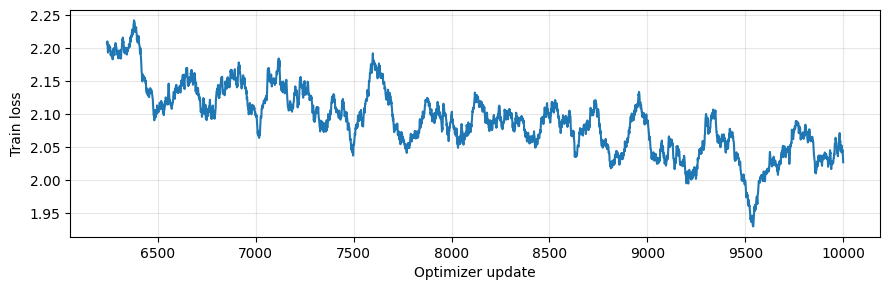

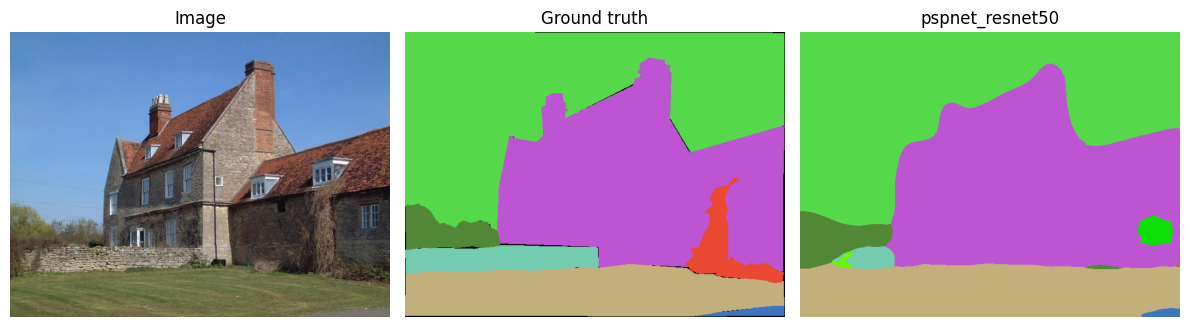

In [8]:
import csv
log_path = OUTPUT / "train.csv"
if log_path.exists():
    with log_path.open() as f:
        rows = list(csv.DictReader(f))
    if rows:
        loss = np.array([float(r["loss"]) for r in rows])
        window = min(100, len(loss))
        smooth = np.convolve(loss, np.ones(window) / window, mode="valid")
        plt.figure(figsize=(9, 3))
        plt.plot([int(r["step"]) for r in rows][window-1:], smooth)
        plt.xlabel("Optimizer update"); plt.ylabel("Train loss"); plt.grid(alpha=.3)
        plt.tight_layout(); plt.savefig(OUTPUT / "training_loss.png", dpi=120); plt.show()
if complete:
    model = lab.make_model(cfg, pretrained=False).to(device)
    lab.load_checkpoint(OUTPUT / "last.pt", model, None, None, lock, device)
    model.eval()
    image_path, mask_path = lab.pairs(ROOT, "validation")[0]
    with Image.open(image_path) as im:
        image = im.convert("RGB")
    pred = lab.predict(model, image, cfg, device)
    target = lab.read_mask(mask_path)
    palette = np.random.default_rng(17).integers(0, 256, (256, 3), dtype=np.uint8)
    palette[255] = 0
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax, view, title in zip(axes, [image, palette[target], palette[pred]], ["Image", "Ground truth", MODEL]):
        ax.imshow(view); ax.set_title(title); ax.axis("off")
    fig.tight_layout(); fig.savefig(OUTPUT / "prediction_example.png", dpi=120); plt.show()
    del model
    import gc
    gc.collect(); torch.cuda.empty_cache()


## 9. Xuất kết quả và lưu phiên

Report ZIP chứa metrics/log/ảnh; **không chứa checkpoint**. Giữ cả thư mục output có last.pt nếu còn cần resume. Trong Kaggle, Save Version/Commit và kiểm tra Output đã có last.pt; phiên mới Add Input output đã lưu, trỏ RESUME_FROM tới file đó, giữ nguyên tên thí nghiệm/cấu hình. Không dựa vào /kaggle/working còn tồn tại sau khi session bị hủy.


In [9]:
archive = lab.export(cfg)
from IPython.display import display, FileLink
display(FileLink(str(archive.relative_to(WORK))))
if (OUTPUT / "summary.csv").exists():
    print((OUTPUT / "summary.csv").read_text())
print("Checkpoint cần giữ:", OUTPUT / "last.pt")


{'model': 'pspnet_resnet50', 'seed': 17, 'step': 10000, 'images': 2000, 'miou': 0.253273072746901, 'pixel_accuracy': 0.7133100216639717, 'training_hours': 11.490279563633054, 'params_training': 49057132, 'params_inference': 46658774, 'gmacs_conv': 99.77987072, 'latency_ms_median': 69.37250900268555, 'peak_allocated_mib': 809.5400390625}
Report: /kaggle/working/pspnet_r50_b6_ade20k_s17_c384_b16_10k_stable_v2_report.zip | checkpoint (save separately): /kaggle/working/pspnet_r50_b6_ade20k_s17_c384_b16_10k_stable_v2/last.pt


/kaggle/working/pspnet_r50_b6_ade20k_s17_c384_b16_10k_stable_v2_report.zip

model,seed,step,images,miou,pixel_accuracy,training_hours,params_training,params_inference,gmacs_conv,latency_ms_median,peak_allocated_mib
pspnet_resnet50,17,10000,2000,0.253273072746901,0.7133100216639717,11.490279563633054,49057132,46658774,99.77987072,69.37250900268555,809.5400390625

Checkpoint cần giữ: /kaggle/working/pspnet_r50_b6_ade20k_s17_c384_b16_10k_stable_v2/last.pt


## 10. Dọn dữ liệu khỏi output

Xóa bản ADE20K đã tải trong /kaggle/working/data để output version chỉ còn checkpoint/log; lần resume sau Add Input sẽ nhanh. Phiên mới tự tải lại dữ liệu nếu cần.

In [10]:
for data_dir in (WORK / "data", WORK / "_resume"):
    if data_dir.exists():
        shutil.rmtree(data_dir)
        print("Đã xóa", data_dir)
print("Output còn lại:", sorted(p.name for p in WORK.iterdir()))

Đã xóa /kaggle/working/data
Đã xóa /kaggle/working/_resume
Output còn lại: ['__notebook__.ipynb', '__pycache__', 'kaggle_segmentation.py', 'pspnet_r50_b6_ade20k_s17_c384_b16_10k_stable_v2', 'pspnet_r50_b6_ade20k_s17_c384_b16_10k_stable_v2_report.zip']


## Ghi chú đánh giá

- So sánh PSPNet, FCN và DeepLabV3 khi cả ba đủ 10.000 updates, cùng dataset, cấu hình và GPU benchmark.
- Backbone chuẩn TorchVision ResNet-50 V1 / OS8; heads khởi tạo mới. Backbone pretrained giống nhau, không dùng segmentation-pretrained weights.
- PPM `{1,2,3,6}` là baseline; `{1,2,3,7}` là lựa chọn khác cần tên output mới. `ppm_bins` được khóa cùng cấu hình để không resume nhầm.
- Crop 384 không cần thỏa điều kiện `(crop-1)%8==0` của code Modal: forward trả logits đúng kích thước input, kể cả kích thước lẻ.
- BatchNorm freeze running statistics; accumulation không tương đương batch thực 16 của nhóm Modal.
- Một seed chưa đo được độ ổn định giữa các lần train. Không so latency T4 trực tiếp với L40S.
- Giữ nguyên hai notebook FCN/DeepLabV3 cũ; source/lock của chúng không bị thay đổi bởi notebook mới này. Nên chạy các notebook trong phiên Kaggle riêng.

Nguồn kiến trúc: [PSPNet tác giả](https://github.com/hszhao/semseg/blob/4f274c3f276778228bc14a4565822d46359f0cc8/model/pspnet.py), [TorchVision FCN/ResNet-50](https://docs.pytorch.org/vision/stable/_modules/torchvision/models/segmentation/fcn.html).
